# Multilingual GPT-2: from implementation to inference

A custom GPT-2 transformer and AdamW optimizer, fine-tuned for natural language inference. Given a **premise** and **hypothesis**, the model generates one of three labels: entailment, contradiction, or neutral.

This notebook presents saved results. Training, datasets, model code, and analysis live in the `multilingual_gpt2` Python package; running these cells does not download weights or retrain models.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from multilingual_gpt2.plots import diagnostic_figures
from multilingual_gpt2.reporting import (
    load_result,
    plot_confusion,
    plot_learning_curve,
    prediction_examples,
    run_summary,
)

root = Path.cwd()
runs = [
    load_result(path)
    for path in sorted(root.glob("results/showcase*/results.json"))
]
assert runs, "Showcase results are missing."
print(f"Loaded {len(runs)} measured runs; no training or downloads required.")

Loaded 2 measured runs; no training or downloads required.


## Verified local experiments

These are newly measured subset runs, not a reproduction of the full-data PDF benchmark. Development accuracy selects the checkpoint; test examples are held out from training. Both early and larger runs remain visible. The majority baseline predicts the most common test label.

In [2]:
display(run_summary(runs))

,training examples,test examples,test accuracy (%),majority baseline (%),valid labels (%),selected epoch
0,1024,256,32.81,34.38,100.0,1
1,8192,512,70.70,33.98,100.0,1


The larger run trained on 8,192 examples and reaches **70.7% test accuracy on 512 examples**, with 72.1% development accuracy. The first 1,024-example run reaches 32.8% test accuracy, below its 34.4% majority baseline. Both verify the workflow; only the larger run demonstrates useful subset performance. Full-data reproduction remains pending.

In [3]:
selected = max(runs, key=lambda run: run["settings"]["train_count"])
display(
    pd.Series(
        {
            key: selected["settings"][key]
            for key in (
                "model",
                "initialization",
                "train_count",
                "dev_count",
                "test_count",
                "seed",
                "max_length",
                "epochs",
                "batch_size",
                "lr",
                "gpu",
                "torch",
            )
        }
    ).to_frame("run settings")
)

,run settings
model,artifacts/gpt2
initialization,pretrained
train_count,8192
dev_count,512
test_count,512
seed,42
max_length,128
epochs,1
batch_size,4
lr,0.00005


## Learning curve

Loss is computed only on the target label. Prompt and padding positions do not contribute. A falling training loss alone is not evidence of improved held-out accuracy.

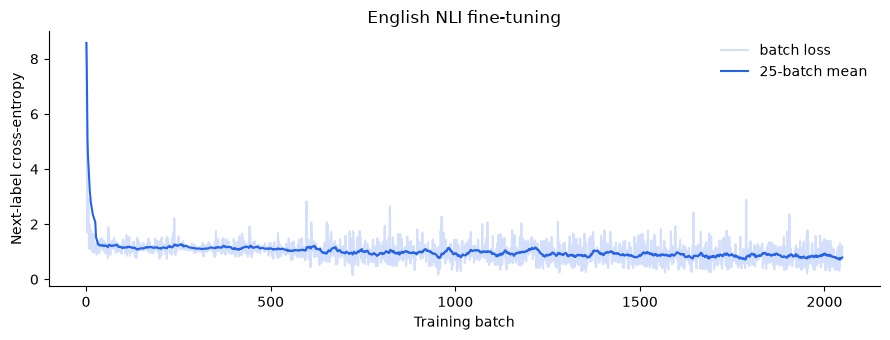

In [4]:
figure = plot_learning_curve(selected)
display(figure)
plt.close(figure)

## Predictions

The first six held-out examples in the recorded evaluation order, including mistakes. No examples are selected by correctness.

In [5]:
pd.set_option("display.max_colwidth", 100)
display(prediction_examples(selected))

,premise,hypothesis,gold,prediction,correct
0,spend it on the ones who who do have a chance,"Give it to everyone, regardless of what they will do with it.",contradiction,contradiction,True
1,"They just didn't like what it was like being black in those days, and that was, you know, I gues...",It was hard to be black in the south.,neutral,neutral,True
2,"Close to the original action and still providing the most vivid testimony to the Klondike days, ...",Whitehorse used mainly horse carriages for transportation.,neutral,neutral,True
3,The museum is not strong on catalogues or labels,The strong point of the museum is the catalogues.,contradiction,entailment,False
4,Levasseur? He smiled a little.,He kept his mouth closed as he smiled a bit.,neutral,contradiction,False
5,"As the Secret Constitution would again reassert itself in American politics, we would also take ...",The Fifteenth Amendment was immediately written off and never passed.,contradiction,contradiction,True


## Held-out classification errors

Every one of the 512 test predictions is counted, including any invalid generated labels. Rows are gold labels; columns are model predictions.

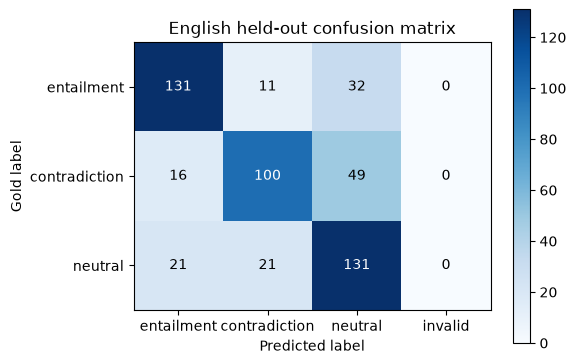

In [6]:
figure = plot_confusion(selected)
display(figure)
plt.close(figure)

## Historical multilingual results

Transcribed from PDF pages 32-34; **not reproduced by the local showcase**. The original comparison mixes test, development subsets, and full development results, so improvements across these columns are not controlled comparisons. Corrected experiments evaluate all variants on the same held-out split.

Fertility is the number of tokenizer subwords per whitespace-estimated word. It is only an approximate cross-language measure, especially for languages without consistent whitespace word boundaries.

In [7]:
historical = load_result(root / "results/historical.json")
display(pd.DataFrame(historical["rows"]).set_index("language"))

,fertility,zero_shot_test_percent,per_language_dev_percent,combined_dev_percent
language,,,,
en,1.11,78.02,NaN,NaN
ar,4.70,37.09,NaN,NaN
bg,5.53,36.57,NaN,NaN
de,2.10,41.52,63.86,61.45
el,6.16,37.86,NaN,NaN
es,1.83,45.55,63.45,64.58
fr,1.75,40.38,65.86,62.85
hi,5.12,36.71,NaN,NaN
ru,5.90,37.80,NaN,NaN


## Recovered multilingual diagnostics

A small integration check of the 8,192-example checkpoint: **24 held-out examples per language**, eight development embeddings per language, seed 42. These tiny samples demonstrate the recovered analyses; they do not establish language rankings or benchmark quality. Calibration renormalizes probabilities over the three NLI labels. Attention shows the first sampled English development example.

In [8]:
diagnostics = load_result(root / "results/diagnostics/summary.json")
display(
    pd.DataFrame(diagnostics["languages"])[
        ["language", "count", "accuracy", "fertility", "ece", "brier"]
    ].set_index("language")
)

,count,accuracy,fertility,ece,brier
language,,,,,
en,24,0.750000,1.105069,0.159430,0.368230
es,24,0.333333,1.838569,0.238899,0.721364
fr,24,0.541667,1.767685,0.203374,0.630359
de,24,0.458333,2.093640,0.138229,0.609626
sw,24,0.250000,2.088325,0.359612,0.892792


### Fertility, representations, and checkpoint comparison

The **reference checkpoint** trained on 8,192 English examples; the **compared checkpoint** trained on 1,024. Both are evaluated on the same 24 test examples per language here, so these numbers differ from their larger showcase test sets. The projection jointly fits the same eight development examples per language from each model. t-SNE distances are qualitative; paired shift magnitudes are computed in the original embedding space.

The correlation and language-family summaries below use only five languages. They are descriptive checks, not evidence of causation or robust cross-language differences. Attention maps use one English development example; head summaries are not corpus averages.

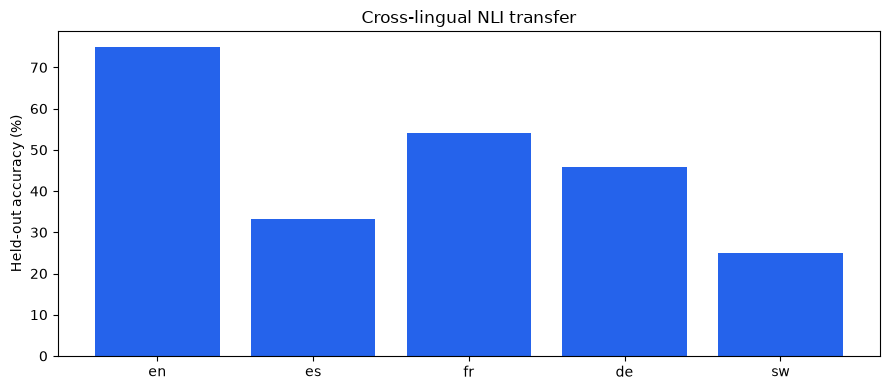

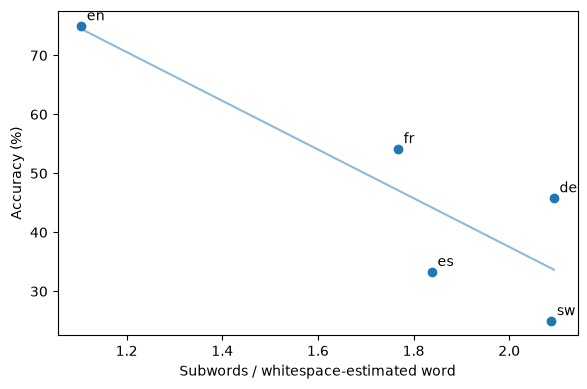

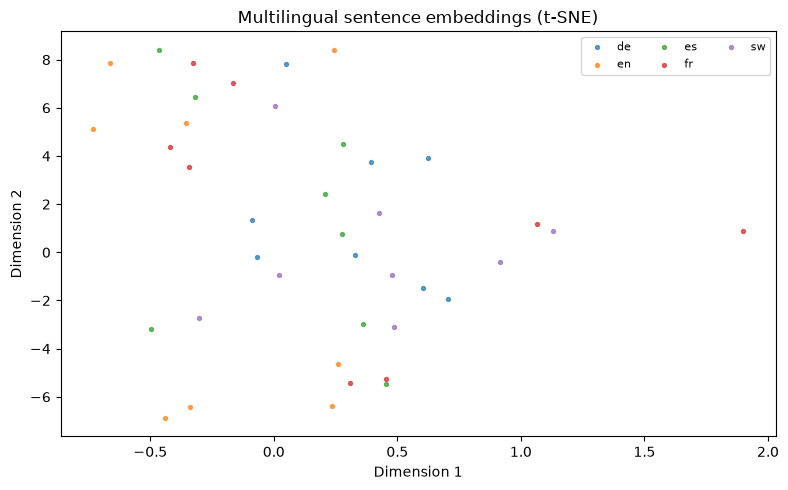

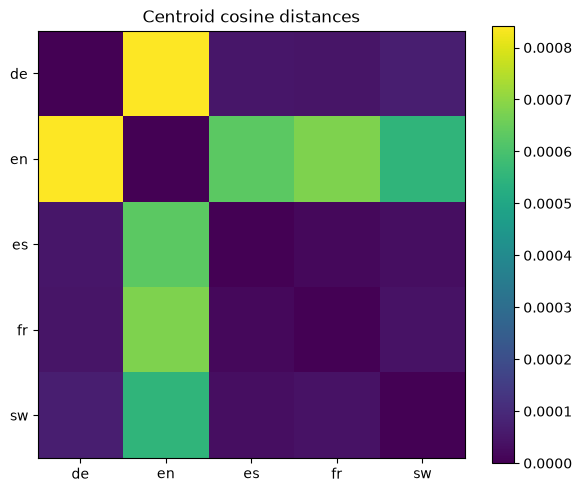

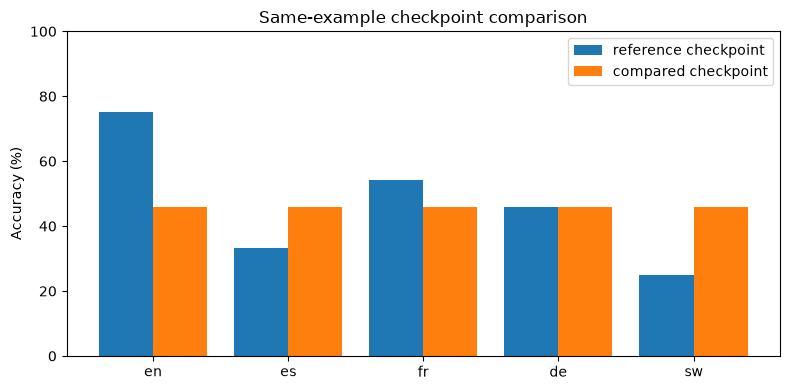

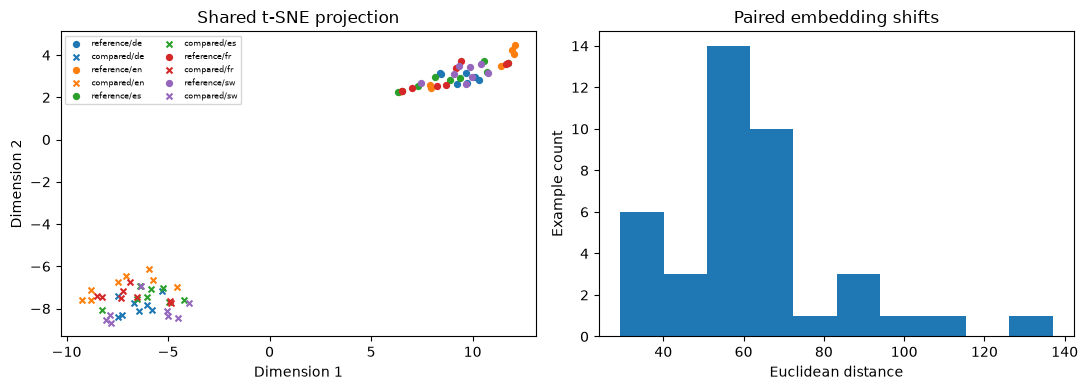

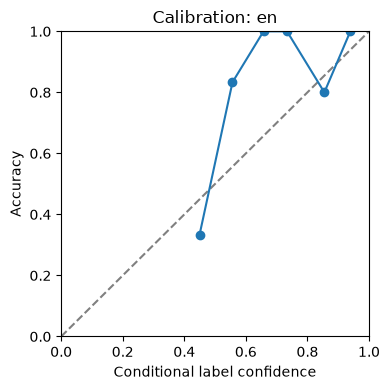

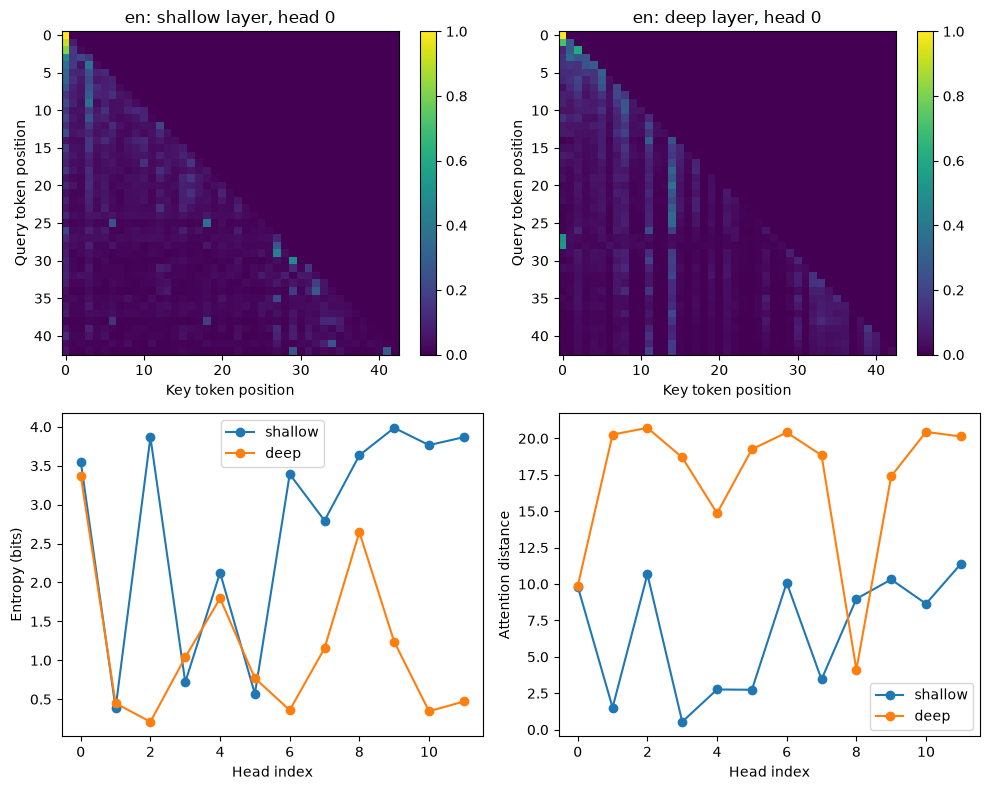

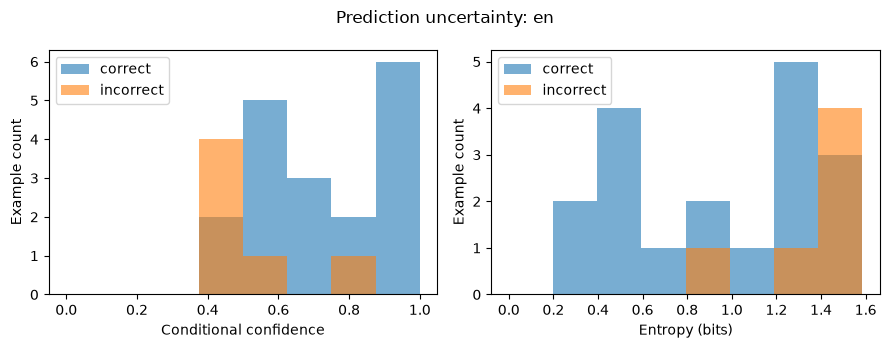

In [9]:
for name, figure in diagnostic_figures(
    root / "results/diagnostics", languages=["en"]
):
    display(figure)
    plt.close(figure)

In [10]:
display(
    pd.DataFrame(
        {
            name: diagnostics[name]
            for name in ("fertility_accuracy", "fertility_entropy")
        }
    ).T
)
display(pd.DataFrame(diagnostics["families"]).T)
embedding = load_result(root / "results/diagnostics/embedding-summary.json")
display(
    pd.Series(
        {key: embedding[key] for key in ("silhouette", "davies_bouldin")}
    ).to_frame("embedding metric")
)

,count,pearson,pearson_p,spearman,spearman_p
fertility_accuracy,5.0,-0.859042,0.062168,-0.7,0.188120
fertility_entropy,5.0,0.890545,0.042749,0.6,0.284757


,languages,mean_accuracy
Indo-European,"[en, es, fr, de]",0.520833
Niger-Congo,[sw],0.25


,embedding metric
silhouette,-0.272774
davies_bouldin,13.347830


In [11]:
attention = [
    load_result(root / f"results/diagnostics/en-attention-{layer}.json")
    for layer in (0, -1)
]
display(
    pd.DataFrame(attention)[
        ["layer", "hypothesis_to_premise", "hypothesis_to_hypothesis"]
    ].set_index("layer")
)

,hypothesis_to_premise,hypothesis_to_hypothesis
layer,,
0,0.468917,0.531083
-1,0.858625,0.141375


### Error inspection

The highest-entropy errors from each language are exported for manual review. Entropy measures uncertainty over the three labels. The displayed examples are selected by that stated rule; unfilled annotation fields remain in the CSV for a human reviewer.

In [12]:
errors = pd.read_csv(root / "results/diagnostics/errors-for-annotation.csv")
display(
    errors[
        [
            "language",
            "premise",
            "hypothesis",
            "gold",
            "prediction",
            "confidence",
            "entropy",
        ]
    ]
    .groupby("language", sort=False)
    .head(1)
)

,language,premise,hypothesis,gold,prediction,confidence,entropy
0,en,The museum is not strong on catalogues or labels,The strong point of the museum is the catalogues.,1,0,0.435725,1.552276
5,es,Eso se encuentra a la sombra del árbol de Apolo.,Se sienta a plena luz del día bajo el sol.,1,2,0.349895,1.582468
10,fr,"Ils n'aimaient simplement pas ce que c'était que d'être noir à l'époque, et c'était, vous savez,...",C'est dur d’être un noir dans le sud.,2,0,0.406549,1.567974
15,de,"Die Verbindung von Geldnamen mit anderen Gewichten ist Ouguiya (Mauretanien), was Unze bedeutet.",Ouguiya wird als ‚Kilogramm‘ übersetzt und nur als eine Einheit der Gewichtsmessung verwendet.,1,2,0.373916,1.579716
20,sw,"Karibu na matukio ya awali na bado kutoa ushahidi wazi zaidi kwa siku za Klondike, boomtown ya D...","Kule Whitehorse, gari za farasi ndizo zilitumika kwa usafiri.",2,0,0.379100,1.577833


## Sentiment prompting

All three prompt modes were executed on 12 examples in each of six languages. The NLI checkpoint produced no recognized sentiment labels: accuracy and coverage are zero. Unknown answers remain in the denominator. This is a measured failure, not evidence that sentiment classification works.

In [13]:
sentiment = load_result(root / "results/diagnostics/sentiment.json")
display(
    pd.DataFrame(sentiment)[
        ["language", "mode", "count", "accuracy", "macro_f1", "coverage"]
    ].set_index(["language", "mode"])
)

count  accuracy  macro_f1  coverage
language mode                                       
arabic   zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
english  zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
french   zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
german   zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
hindi    zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
spanish  zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0

## Core experiment execution checks

All ten training paths were run with the small profile. Each uses one epoch and at most 32 training examples per language, including the nominal two-epoch variants; these checks validate execution and **cannot compare hyperparameters or multilingual training quality**. The toy loss and continuation below come from that actual small pretraining run.

,train_count,epochs,test_count,test_accuracy,status
job,,,,,
combined,160,1,60.0,0.500000,reproduced_small_run
de,32,1,12.0,0.416667,reproduced_small_run
english,32,1,12.0,0.583333,reproduced_small_run
english-batch8,32,1,12.0,0.500000,reproduced_small_run
english-epochs2,32,1,12.0,0.583333,reproduced_small_run
english-lr1e5,32,1,12.0,0.166667,reproduced_small_run
es,32,1,12.0,0.416667,reproduced_small_run
fr,32,1,12.0,0.500000,reproduced_small_run
pretrain,32,1,NaN,NaN,reproduced_small_run


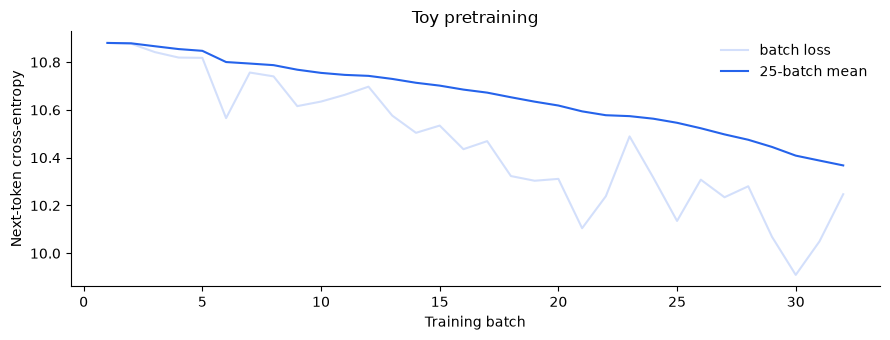

Toy continuation: ' the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the'


In [14]:
core = load_result(root / "results/core-small.json")
display(pd.DataFrame(core["runs"]).set_index("job"))
figure = plot_learning_curve(core["pretraining"])
display(figure)
plt.close(figure)
print("Toy continuation:", repr(core["pretraining"]["generation"]))

## Reconstruction stage and missing evidence

The core and extended workflow implementations are reconstructed and tested. This notebook now exposes their available measured analyses and visuals. **Full experimental reproduction is incomplete.** Full-data benchmark runs remain unexecuted; the original synthetic tone, style-transfer, and Mandarin files are absent. Those workflows passed integration checks with clearly fictional fixtures; their fixture scores are omitted because they are not research evidence.

Synthetic generation is an explicit bounded opt-in command; no paid API calls have been made. The original PDF is unchanged, and historical results remain labeled separately. The [reconstruction log](docs/reconstruction.md) maps source sections, corrections, verification and limitations. [README.md](README.md) documents all execution commands.

In [15]:
validation = load_result(root / "results/validation.json")
display(
    pd.DataFrame(validation["tone_fixture_checks"]).T.rename(
        columns={"count": "fixture evaluation rows"}
    )
)
print(
    "Original synthetic-data results: unavailable; "
    "full-data benchmarks: pending."
)

,completed,fixture evaluation rows
tone,True,7
pragmatic,True,56
style,True,4
translation,True,32


Original synthetic-data results: unavailable; full-data benchmarks: pending.
